# IKpy Quickstart #

Import the IKPy module : 

In [49]:
import ikpy.chain
import numpy as np
import ikpy.utils.plot as plot_utils

The basic element of IKPy is the kinematic `Chain`.
To create a chain from an URDF file : 

In [50]:
# will give warnings, that's OK
my_chain = ikpy.chain.Chain.from_urdf_file("./ur5/ur5_gripper.urdf")

/local/hammits/lab-2-ik/.pixi/envs/default/lib/python3.12/site-packages/ikpy/chain.py:60: UserWarning: Link Base link (index: 0) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive
  warnings.warn("Link {} (index: {}) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive".format(link.name, link_index))
/local/hammits/lab-2-ik/.pixi/envs/default/lib/python3.12/site-packages/ikpy/chain.py:60: UserWarning: Link ee_fixed_joint (index: 7) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive
  warnings.warn("Link {} (index: {}) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive".format(link.name, 

# Inverse kinematics

In Inverse Kinematics, you want the "end effector" of your robot to reach a specific 3D position (and in general, orientation) in space. The end effector is the final link of the robot arm, furthest from the base, and possibly a tool that is attached (a gripper in our robot model).

To have a more general representation of position, IKPy works with homogeneous coordinates. Homogenous coordinates are represented as a 4x4 matrix storing both position and orientation. Here we only consider (x,y,z) position, not orientation of the chain.

In [51]:
# define target X, Y, Z coordinate
target_position = [ 1.0872, 0, 0]

In [52]:
# run inverse kinematics solver
print("The joint angles are : ", my_chain.inverse_kinematics(target_position))

The joint angles are :  [ 0.00000000e+00 -1.33227902e-01  8.25717421e-02 -4.96493013e-05
 -2.27617171e+00 -1.36756048e+00  0.00000000e+00  0.00000000e+00]


You can check that the Inverse Kinematics is correct by comparing with the original position vector : 

In [53]:
# run forward kinematics on the inverse kinematics solution to verify
real_frame = my_chain.forward_kinematics(my_chain.inverse_kinematics(target_position))
print("Computed position vector : %s, goal position vector : %s" % (real_frame[:3, 3], target_position))

Computed position vector : [ 9.46755389e-01 -2.38414298e-08  1.15181567e-02], goal position vector : [1.0872, 0, 0]


In [74]:
def sphere(n, radius):
    count = 0;
    points = [];
    while count < n:
        point = np.random.randn(3);
        length = np.linalg.norm(point);
        for x in range(3):
            point[x] = (point[x]/length)*radius;
        count += 1;
        points.append(point);
    return points;

targets = sphere(100, radius=2.0)

reached = []
for target in targets:
    joints = my_chain.inverse_kinematics(target);
    fk = my_chain.forward_kinematics (joints);
    reached.append(fk[:3, 3]);

reached = np.array(reached);
print(reached);

[[-0.70795486  0.41662412 -0.38791346]
 [-0.01524424  0.32898219 -0.8018585 ]
 [ 0.00552139 -0.32702453  0.98101007]
 [ 0.54459446  0.46136935 -0.53768154]
 [-0.91237147  0.26412967  0.07546003]
 [ 0.31178803  0.44641581  0.86753874]
 [-0.28982208  0.76446711 -0.39454242]
 [ 0.84790752  0.2164637  -0.280395  ]
 [ 0.30162687 -0.90058692  0.10755142]
 [ 0.620313   -0.14293187 -0.615934  ]
 [ 0.66648408 -0.60707502 -0.21022828]
 [-0.48720079 -0.08624872 -0.72174815]
 [-0.25512336 -0.88062659 -0.15940235]
 [-0.16300734  0.02458074  1.02467931]
 [ 0.75183069  0.21388105  0.62895467]
 [-0.58411539  0.67803165  0.40768082]
 [-0.08766295  0.93873262 -0.02690185]
 [-0.57102238 -0.63936136  0.49845637]
 [ 0.03107544 -0.57379301 -0.66726003]
 [ 0.06558856 -0.14762519  1.02525663]
 [ 0.28106317  0.14085473 -0.80724341]
 [-0.31863996  0.88987395  0.18385207]
 [ 0.05650225  0.94322257  0.18669123]
 [-0.60872767 -0.12907702  0.80690799]
 [ 0.65429727  0.68445985  0.16520929]
 [ 0.0400921   0.78906057

# Plotting
And finally plot the result : 

In [78]:
from ikpy.utils import geometry
def get_joints(joints):
    nodes = []
    # "chain" is the Chain object returned by ikpy when it loads URDF file
    # "joints" is the solution from your inverse kinematics solver
    transformation_matrixes = my_chain.forward_kinematics(joints, full_kinematics=True)
    
    # Get the nodes and the orientation from the transformation matrix
    for (index, link) in enumerate(my_chain.links):
        (node, orientation) = geometry.from_transformation_matrix(transformation_matrixes[index])
    
        # Add node corresponding to the link
        nodes.append(node)
    return nodes;

[array([0., 0., 0., 1.]), array([0.      , 0.      , 0.089159, 1.      ]), array([0.      , 0.13585 , 0.089159, 1.      ])]
True
True
True
True
True
True
True
True


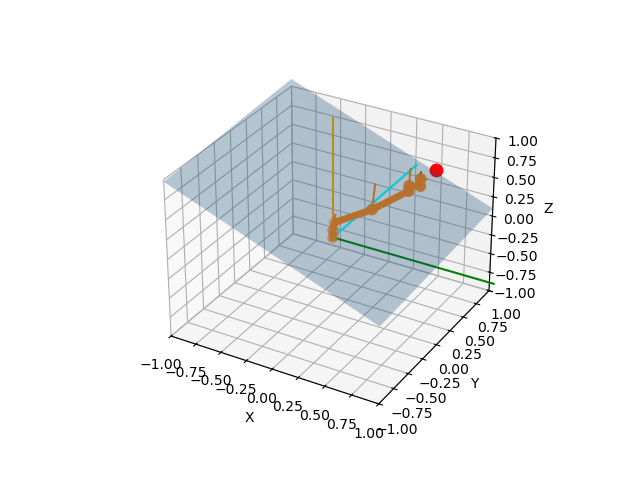

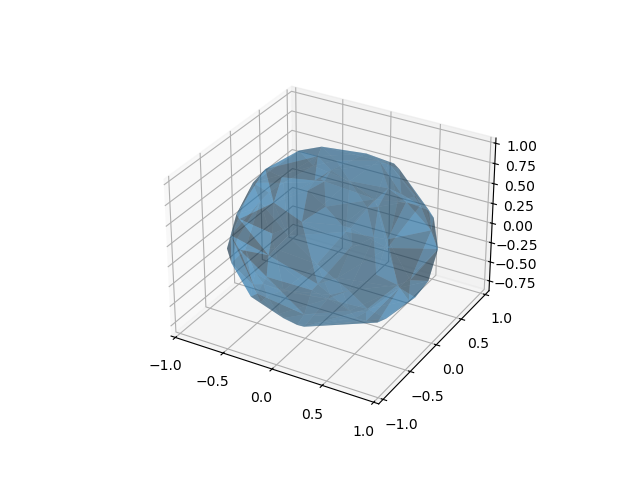

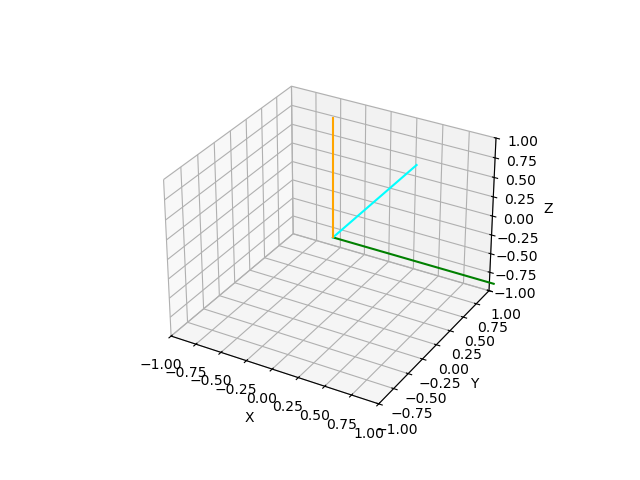

In [98]:
%matplotlib notebook
%matplotlib ipympl

from scipy.spatial import ConvexHull    
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

hull = ConvexHull(reached)
fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.plot_trisurf(reached[:,0], reached[:,1], reached[:,2], triangles=hull.simplices, alpha=0.4)
fig, ax = plot_utils.init_3d_figure()

points = [[0.65612, 0.53440, 0.24175],
           [0.62279, 0.51946, 0.25744],
           [0.61216, 0.53959, 0.26394]]

p0, p1, p2 = points
x0, y0, z0 = p0
x1, y1, z1 = p1
x2, y2, z2 = p2

ux, uy, uz = u = [x1-x0, y1-y0, z1-z0]
vx, vy, vz = v = [x2-x0, y2-y0, z2-z0]

u_cross_v = [uy*vz-uz*vy, uz*vx-ux*vz, ux*vy-uy*vx]

point  = np.array(p0)
normal = np.array(u_cross_v)

d = -point.dot(normal)


zero_joints = np.zeros(len(my_chain.links))
print(get_joints(zero_joints)[:3])

# plot the surface
fig, ax = plot_utils.init_3d_figure()
xx, yy = np.meshgrid(np.linspace(-1,1,10), np.linspace(-1,1,10))
zz = (-normal[0] * xx - normal[1] * yy - d) * 1. / normal[2]
ax.plot_surface(xx,yy,zz, alpha=0.3)
for node in get_joints(zero_joints):
    v = node[:3]- point
    
    dot_product = np.dot(v,normal)
    print(dot_product > 0)

my_chain.plot(my_chain.inverse_kinematics(target_position), ax, target=target_position)

plt.show()
